In [1]:
'''
Santa 2026 | Can a Shared Base Pay for Itself?

Rebuild selected target groups as q × B + r using an existing or
synthesized base. Count removed instructions, added instructions and
register allocation failures before accepting a shorter program.
'''

# Santa 2026 · Can a Shared Base Pay for Itself?

**A matched experiment on 20 scored puzzles.** Every attempt starts from the same **128,485-instruction** reference. The two arms differ in how they choose targets and use the same arithmetic search.

| Rule | How it selects a block |
|:---|:---|
| Nearby multiples | Four targets have small residuals around multiples of a common base |
| Shared dependencies | Four targets share a dependency cone in the reference graph |

Within each selected group, the search can rebuild two, three, or four targets. The rest of the portfolio remains available as the fallback for every puzzle.

In [2]:
'''
Credits

Baseline programs come from Ertuğrul Özer's Santa 2026 Verified
Programs, version 506. The Kaggle listing records its license as Unknown.
https://www.kaggle.com/datasets/ozertuu/santa-2026-verified-programs/versions/506

Ishan Karnick's hidden-base analysis motivated the nearby-multiples arm.
https://www.kaggle.com/code/ishankarnick/santa-2026-hidden-bases-and-what-didn-t-work

The arithmetic search, experimental comparison and figures are
implemented here. The exact referee and register compiler come from
our previous Santa 2026 notebooks.
'''

## 1 · Configuration and exact referee

In [3]:
EXPERIMENT_SLUG = '07_affine_blocks'
PUZZLES_PER_COHORT = 10
GROUPS_PER_RULE = 3
ANCHOR_BUDGET = 24
TWO_STEP_BASE_LIMIT = 64

In [4]:
import csv
import hashlib
import json
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path
from statistics import median
from tempfile import TemporaryDirectory
from time import perf_counter


COMPETITION = 'santa-2026'
DATASET_OWNER = 'ozertuu'
DATASET_SLUG = 'santa-2026-verified-programs'
DATASET_VERSION = 506
PORTFOLIO_SHA256 = '4560d52245b3eca32f229a03a26b368c1fb506e0aa3ffa950607434e5b9bd0e7'
EXPECTED_SCORE = 128_485
SUBMISSION_COLUMNS = ['id', 'program']
MAX_INSTRUCTIONS = 4_096
MAX_PROGRAM_BYTES = 131_072

Instruction = tuple[str, int, int, int]
Program = tuple[Instruction, ...]


@dataclass(frozen=True)
class Config:
    puzzles_csv: Path
    portfolio_csv: Path
    output_csv: Path

    @classmethod
    def discover(cls) -> 'Config':
        kaggle = Path('/kaggle/input')
        if kaggle.is_dir():
            puzzles = cls.locate(kaggle, COMPETITION, 'puzzles.csv')
            programs = cls.locate(kaggle, DATASET_SLUG, 'best_programs.csv')
            return cls(puzzles, programs, Path('/kaggle/working/submission.csv'))

        root = Path.cwd()
        competition_dir = root / 'competitions' / 'public-comp' / COMPETITION
        if competition_dir.is_dir():
            root = competition_dir
        elif root.name == EXPERIMENT_SLUG and root.parent.name == COMPETITION:
            root = root.parent
        data = root / 'data'
        return cls(
            data / 'puzzles.csv',
            data / DATASET_SLUG / 'best_programs.csv',
            root / 'working' / EXPERIMENT_SLUG / 'submission.csv',
        )

    @staticmethod
    def locate(root: Path, slug: str, filename: str) -> Path:
        matches = [path for path in root.rglob(filename) if slug in path.parent.parts]
        if len(matches) != 1:
            raise FileNotFoundError(
                f'Expected one {slug}/{filename} input, found {len(matches)}'
            )
        return matches[0]

    def check_inputs(self) -> None:
        if not self.puzzles_csv.is_file():
            raise FileNotFoundError(
                f'Attach the {COMPETITION} competition data or copy puzzles.csv '
                f'to {self.puzzles_csv}'
            )
        if not self.portfolio_csv.is_file():
            raise FileNotFoundError(
                f'Attach {DATASET_OWNER}/{DATASET_SLUG} version {DATASET_VERSION} '
                f'or copy best_programs.csv to {self.portfolio_csv}'
            )
        digest = hashlib.sha256(self.portfolio_csv.read_bytes()).hexdigest()
        if digest != PORTFOLIO_SHA256:
            raise ValueError(
                f'Expected {DATASET_SLUG} version {DATASET_VERSION}. '
                f'Unexpected SHA-256 for {self.portfolio_csv}: {digest}'
            )

In [5]:
@dataclass(frozen=True)
class Puzzle:
    starts: tuple[int, ...]
    targets: frozenset[int]
    value_limit: int
    register_count: int

    @classmethod
    def from_row(cls, row: dict[str, str]) -> 'Puzzle':
        return cls(
            tuple(json.loads(row['starting_values'])),
            frozenset(json.loads(row['targets'])),
            int(row['value_limit']),
            int(row['registers']),
        )


@dataclass(frozen=True)
class ProgramProfile:
    length: int
    operations: Counter[str]
    peak_value: int
    populated_registers: int


class Calculator:
    '''Read both sources before writing and remember targets across overwrites.'''

    def replay(self, puzzle: Puzzle, program: Program) -> ProgramProfile:
        if len(program) > MAX_INSTRUCTIONS:
            raise ValueError('Program exceeds the instruction limit')

        registers = list(puzzle.starts) + [None] * (
            puzzle.register_count - len(puzzle.starts)
        )
        missing = set(puzzle.targets).difference(puzzle.starts)
        operations = Counter()
        peak_value = max(puzzle.starts, default=0)

        for number, instruction in enumerate(program, start=1):
            if len(instruction) != 4:
                raise ValueError(f'Step {number}: expected four instruction fields')
            op, left, right, dest = instruction
            if any(type(index) is not int or not 0 <= index < puzzle.register_count
                   for index in (left, right, dest)):
                raise ValueError(f'Step {number}: register index out of range')

            a, b = registers[left], registers[right]
            if a is None or b is None:
                raise ValueError(f'Step {number}: undefined source register')
            if op == '+':
                value = a + b
            elif op == '-':
                value = a - b
            elif op == '*':
                value = a * b
            elif op == '/' and a % b == 0:
                value = a // b
            else:
                raise ValueError(f'Step {number}: unsupported operation or inexact division')

            if not 1 <= value <= puzzle.value_limit:
                raise ValueError(f'Step {number}: result outside the value limit')
            registers[dest] = value
            missing.discard(value)
            operations[op] += 1
            peak_value = max(peak_value, value)

        if missing:
            raise ValueError(f'{len(missing)} missing targets')

        '''
        Defined registers stay populated after a write, so the final count
        is also the peak populated count for the program.
        '''
        return ProgramProfile(
            len(program), operations, peak_value,
            sum(value is not None for value in registers),
        )

In [6]:
class PortfolioPipeline:
    def __init__(self, config: Config):
        self.config = config
        self.calculator = Calculator()

    def load_puzzles(self) -> dict[str, Puzzle]:
        with self.config.puzzles_csv.open(encoding='utf-8-sig', newline='') as file:
            rows = list(csv.DictReader(file))
        puzzles = {row['id']: Puzzle.from_row(row) for row in rows}
        expected = {f'scored_{index:04d}' for index in range(1, 1_001)}
        if len(rows) != len(expected) or puzzles.keys() != expected:
            raise ValueError('Expected the 1,000 scored puzzle IDs exactly once')
        return puzzles

    def verify(
        self, path: Path, puzzles: dict[str, Puzzle],
    ) -> tuple[dict[str, Program], dict[str, ProgramProfile]]:
        programs, profiles = {}, {}
        with path.open(encoding='utf-8', newline='') as file:
            reader = csv.reader(file)
            if next(reader, None) != SUBMISSION_COLUMNS:
                raise ValueError(f'{path}: expected the id,program header')
            for row in reader:
                if len(row) != 2:
                    raise ValueError(f'{path}: expected two fields at line {reader.line_num}')
                puzzle_id, cell = row
                if puzzle_id not in puzzles or puzzle_id in programs:
                    raise ValueError(f'{path}: unexpected or duplicate ID {puzzle_id}')
                if len(cell.encode('utf-8')) > MAX_PROGRAM_BYTES:
                    raise ValueError(f'{puzzle_id}: program cell exceeds the byte limit')
                try:
                    payload = json.loads(cell)
                    if type(payload) is not list or any(type(step) is not list for step in payload):
                        raise ValueError('Expected a JSON array of instruction arrays')
                    program = tuple(tuple(step) for step in payload)
                    profiles[puzzle_id] = self.calculator.replay(puzzles[puzzle_id], program)
                except ValueError as error:
                    raise ValueError(f'{puzzle_id}: {error}') from error
                programs[puzzle_id] = program
        if programs.keys() != puzzles.keys():
            raise ValueError(f'{path}: portfolio is missing scored puzzle IDs')
        return programs, profiles

    def export(self, programs: dict[str, Program], puzzles: dict[str, Puzzle]) -> None:
        output = self.config.output_csv
        output.parent.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=output.parent) as directory:
            temporary = Path(directory) / output.name
            with temporary.open('w', encoding='utf-8', newline='') as file:
                writer = csv.writer(file)
                writer.writerow(SUBMISSION_COLUMNS)
                for puzzle_id in sorted(programs):
                    cell = json.dumps(programs[puzzle_id], separators=(',', ':'))
                    writer.writerow((puzzle_id, cell))
            written, _ = self.verify(temporary, puzzles)
            if written != programs:
                raise RuntimeError('The exported programs differ from the verified input')
            temporary.replace(output)

In [7]:
@dataclass(frozen=True)
class Operation:
    operator: str
    left: int
    right: int


@dataclass
class ProgramGraph:
    values: dict[int, int]
    recipes: dict[int, Operation]
    roots: set[int]
    users: dict[int, set[int]]

    @classmethod
    def from_program(cls, puzzle: Puzzle, program: Program) -> 'ProgramGraph':
        registers = [-index - 1 for index in range(len(puzzle.starts))]
        registers += [None] * (puzzle.register_count - len(registers))
        values = {-index - 1: value for index, value in enumerate(puzzle.starts)}
        recipes = {}
        users = {node: set() for node in values}
        seen = set(puzzle.starts)
        roots = set()

        '''
        Node IDs leave room to insert one helper immediately before a consumer.
        Each node identifies a single write, even when a register is overwritten.
        '''
        for index, (operator, a, b, dest) in enumerate(program):
            node = index * 2 + 1
            left, right = registers[a], registers[b]
            value = SharedHelperSearch.apply(operator, values[left], values[right])
            values[node] = value
            recipes[node] = Operation(operator, left, right)
            users[node] = set()
            users[left].add(node)
            users[right].add(node)
            if value in puzzle.targets and value not in seen:
                roots.add(node)
            seen.add(value)
            registers[dest] = node

        return cls(values, recipes, roots, users)


class RegisterCompiler:
    '''Try the original order and optionally a dependency-driven schedule.'''

    def prepare(
        self, recipes: dict[int, Operation], roots: set[int],
    ) -> tuple[dict[int, Operation], Counter]:
        required = {}
        remaining = Counter()
        pending = list(roots)
        while pending:
            node = pending.pop()
            if node < 0 or node in required:
                continue
            operation = recipes[node]
            required[node] = operation
            for parent in {operation.left, operation.right}:
                remaining[parent] += 1
                pending.append(parent)
        return required, remaining

    def compile(
        self, puzzle: Puzzle, required: dict[int, Operation], remaining: Counter,
        *, reorder: bool,
    ) -> Program | None:
        remaining = remaining.copy()
        slots = {
            -index - 1: index for index in range(len(puzzle.starts))
            if remaining[-index - 1]
        }
        free = set(range(puzzle.register_count)).difference(slots.values())
        program = []
        fixed = iter(sorted(required))

        if reorder:
            children = {node: [] for node in required}
            parents_left = {}
            for node, operation in required.items():
                computed_parents = {
                    p for p in (operation.left, operation.right) if p >= 0
                }
                parents_left[node] = len(computed_parents)
                for parent in computed_parents:
                    children[parent].append(node)
            ready = {node for node in required if not parents_left[node]}

        def priority(node: int) -> tuple[int, int]:
            operation = required[node]
            released = sum(
                remaining[parent] == 1 for parent in {operation.left, operation.right}
            )
            return int(remaining[node] > 0) - released, node

        for _ in required:
            if reorder:
                node = min(ready, key=priority)
                ready.remove(node)
            else:
                node = next(fixed)
            operation = required[node]
            left, right = slots[operation.left], slots[operation.right]
            for parent in {operation.left, operation.right}:
                remaining[parent] -= 1
                if not remaining[parent]:
                    free.add(slots.pop(parent))
            if not free:
                return None
            dest = free.pop()
            program.append((operation.operator, left, right, dest))
            if remaining[node]:
                slots[node] = dest
            else:
                free.add(dest)
            if reorder:
                for child in children[node]:
                    parents_left[child] -= 1
                    if not parents_left[child]:
                        ready.add(child)
        return tuple(program)


class SharedHelperSearch:
    @staticmethod
    def apply(operator: str, left: int, right: int) -> int:
        if operator == '+':
            return left + right
        if operator == '-':
            return left - right
        if operator == '*':
            return left * right
        return left // right

    @staticmethod
    def inverse(result: int, other: int, limit: int):
        if result > other:
            yield result - other, '+', True
        if result + other <= limit:
            yield result + other, '-', True
        if other > result:
            yield other - result, '-', False
        if result % other == 0:
            yield result // other, '*', True
        if result * other <= limit:
            yield result * other, '/', True
        if other % result == 0:
            yield other // result, '/', False

In [8]:
class FrontierStudy:
    @staticmethod
    def pressure_trace(recipes: dict[int, Operation], order=None) -> list[int]:
        dependencies = {
            node: {recipe.left, recipe.right} for node, recipe in recipes.items()
        }
        remaining = Counter(parent for row in dependencies.values() for parent in row)
        live = sum(parent < 0 for parent in remaining)
        pressure = []
        for node in (sorted(recipes) if order is None else order):
            for parent in dependencies[node]:
                remaining[parent] -= 1
                if not remaining[parent]:
                    live -= 1
            pressure.append(live + 1)
            if remaining[node]:
                live += 1
        return pressure

## 2 · Selection and synthesis

The multiples rule tests small quotients for close residuals. The dependency rule finds values needed by only a few targets and prioritizes groups that free more of the original graph. A block can read values retained by the rest of the program, provided those values do not depend on a selected target.

The search tries floor and ceiling quotients, so either sign of the residual is allowed. Bases may already exist or take up to two instructions to build. Quotients and residuals may already exist or take one instruction. A single chosen recipe per newly constructed constant and a bounded anchor shortlist keep this a pilot. Several formulas may share an intermediate, so the final graph is counted after removing dead operations.

In [9]:
from dataclasses import replace
from itertools import combinations, product


class TargetGroups:
    @staticmethod
    def mask_support(graph: ProgramGraph) -> tuple[list[int], Counter]:
        roots = sorted(graph.roots)
        masks = Counter()
        for index, node in enumerate(roots):
            masks[node] |= 1 << index
        for node in sorted(graph.recipes, reverse=True):
            step = graph.recipes[node]
            for parent in {step.left, step.right}:
                masks[parent] |= masks[node]
        return roots, Counter(masks[node] for node in graph.recipes if masks[node])

    @staticmethod
    def shared(graph: ProgramGraph) -> list[tuple[int, ...]]:
        roots, support = TargetGroups.mask_support(graph)
        small = {mask: count for mask, count in support.items() if 2 <= mask.bit_count() <= 4}
        private = {i: support[1 << i] for i in range(len(roots))}
        ranked = {}
        for mask in small:
            start = tuple(i for i in range(len(roots)) if mask & (1 << i))
            extras = sorted(
                (i for i in private if i not in start), key=lambda i: (-private[i], i),
            )[:6]
            for more in combinations(extras, 4 - len(start)):
                group = tuple(sorted(start + more))
                joined = sum(1 << i for i in group)
                count = sum(n for bits, n in support.items() if bits & joined == bits)
                sharing = sum(n for bits, n in small.items() if bits & joined == bits)
                ranked[group] = (count, sharing)
        ordered = sorted(ranked, key=lambda g: (-ranked[g][0], -ranked[g][1], g))
        return [tuple(roots[i] for i in group) for group in ordered[:GROUPS_PER_RULE]]

    @staticmethod
    def multiples(graph: ProgramGraph) -> list[tuple[int, ...]]:
        roots = sorted(graph.roots)
        targets = [(node, graph.values[node]) for node in roots]
        ranked = {}
        bases = {
            (value + q//2) // q for _, value in targets for q in range(1, 33)
            if value >= 2*q
        }
        for base in bases:
            hits = []
            for node, target in targets:
                q = (target + base//2) // base
                error = abs(target - q*base)
                if 1 <= q <= 128 and error*512 <= base:
                    hits.append((error, node))
            if len(hits) >= 4:
                nearest = sorted(hits)[:4]
                group = tuple(sorted(node for _, node in nearest))
                fit = (len(hits), -sum(error for error, _ in nearest) / base)
                ranked[group] = max(ranked.get(group, rank_floor), fit)
        ordered = sorted(ranked, key=lambda group: (-ranked[group][0], -ranked[group][1], group))
        return ordered[:GROUPS_PER_RULE]


rank_floor = (0, float('-inf'))


@dataclass(frozen=True)
class Block:
    graph: ProgramGraph
    roots: tuple[int, ...]
    fixed: dict[int, Operation]
    inputs: dict[int, int]

    @classmethod
    def make(cls, graph: ProgramGraph, roots: tuple[int, ...]) -> 'Block':
        selected = set(roots)
        fixed = {}
        stack = list(graph.roots - selected)
        while stack:
            node = stack.pop()
            if node < 0 or node in fixed or node in selected:
                continue
            recipe = graph.recipes[node]
            fixed[node] = recipe
            stack.extend((recipe.left, recipe.right))

        '''
        A replacement can use retained values that do not depend on any
        selected output. This keeps all generated recipes acyclic.
        '''
        downstream = selected.copy()
        for node, recipe in sorted(graph.recipes.items()):
            if {recipe.left, recipe.right} & downstream:
                downstream.add(node)
        available = {
            value: node for node, value in graph.values.items()
            if (node < 0 or node in fixed) and node not in downstream
        }
        return cls(graph, roots, fixed, available)


@dataclass(frozen=True)
class Formula:
    quotient: int
    remainder: int
    product: int
    cost: int


@dataclass(frozen=True)
class Example:
    puzzle_id: str
    base: int
    targets: tuple[int, ...]
    forms: tuple[Formula, ...]
    removed: int
    inserted: int


class AffineSearch:
    def __init__(self, calculator: Calculator):
        self.compiler = RegisterCompiler()
        self.calculator = calculator

    @staticmethod
    def one_step(pool: dict[int, int], limit: int) -> dict[int, Operation]:
        rows = sorted(pool.items())
        dictionary = {}
        for i, (a, left) in enumerate(rows):
            for j in range(i + 1):
                b, right = rows[j]
                values = [
                    (a + b, '+'), (a - b, '-'), (a * b, '*'),
                    (a // b if a % b == 0 else 0, '/'),
                ]
                for value, operator in values:
                    if 1 <= value <= limit and value not in pool:
                        dictionary.setdefault(value, Operation(operator, left, right))
        return dictionary

    @staticmethod
    def bases(targets, pool, limit):
        proposed = {value for value in pool if value > 1}
        quotients = set(range(1, 65)) | {value for value in pool if 64 < value <= 256}
        for target in targets:
            for q in quotients:
                base = target // q
                proposed.update(value for value in (base, base + 1) if 1 < value <= limit)
        return sorted(proposed)

    @staticmethod
    def base_recipe(value, pool, dictionary, limit):
        for fixed in pool:
            for intermediate, operator, first in SharedHelperSearch.inverse(value, fixed, limit):
                if intermediate in dictionary:
                    return intermediate, operator, fixed, first
        return None

    @staticmethod
    def formulas(target, base, pool, dictionary, limit):
        choices = []
        quotient = target // base
        for q in (quotient, quotient + 1):
            if q < 1:
                continue
            product = base*q
            if product > limit:
                continue
            remainder = target-product
            build_product = q > 1 and product not in pool
            necessary = {q} if build_product else set()
            if remainder:
                necessary.add(abs(remainder))
            new = necessary - pool.keys()
            if any(value not in dictionary for value in new):
                continue
            cost = len(new) + int(build_product) + bool(remainder)
            choices.append(Formula(q, remainder, product, cost))
        return sorted(choices, key=lambda form: (form.cost, abs(form.remainder), form.quotient))

    @staticmethod
    def construct(block, base, forms, dictionary, base_recipe):
        recipes = block.fixed.copy()
        values = block.inputs.copy()
        next_id = max(block.graph.recipes) + 1

        def emit(value, recipe):
            nonlocal next_id
            if value not in values:
                values[value] = next_id
                recipes[next_id] = recipe
                next_id += 1
            return values[value]

        def fetch(value):
            if value in values:
                return values[value]
            return emit(value, dictionary[value])

        aliases = {}
        if base_recipe is None:
            anchor = fetch(base)
        else:
            intermediate, operator, fixed, first = base_recipe
            seed = fetch(intermediate)
            other = fetch(fixed)
            left, right = (seed, other) if first else (other, seed)
            anchor = emit(base, Operation(operator, left, right))
        for root, formula in zip(block.roots, forms):
            if formula.product in values:
                product = values[formula.product]
            elif formula.quotient == 1:
                product = anchor
            else:
                q = fetch(formula.quotient)
                product = emit(formula.product, Operation('*', anchor, q))
            result = product
            if formula.remainder:
                remainder = fetch(abs(formula.remainder))
                operator = '+' if formula.remainder > 0 else '-'
                result = emit(block.graph.values[root], Operation(operator, product, remainder))
            aliases[root] = result

        roots = {aliases.get(root, root) for root in block.graph.roots}
        rewritten = {
            node: Operation(step.operator, aliases.get(step.left, step.left),
                            aliases.get(step.right, step.right))
            for node, step in recipes.items()
        }
        return rewritten, roots

    def search(self, puzzle, baseline, graph, roots, stats, traces, examples, pid):
        block = Block.make(graph, roots)
        targets = [graph.values[node] for node in roots]
        pool = block.inputs
        dictionary = self.one_step(pool, puzzle.value_limit)
        scores = []
        proposed = self.bases(targets, pool, puzzle.value_limit)
        stats['bases'] += len(proposed)
        deferred = 0
        for base in proposed:
            forms = [self.formulas(t, base, pool, dictionary, puzzle.value_limit) for t in targets]
            if not all(forms):
                continue
            stats['match_all_targets'] += 1
            recipe = None
            if base not in pool and base not in dictionary:
                if deferred >= TWO_STEP_BASE_LIMIT:
                    continue
                deferred += 1
                recipe = self.base_recipe(base, pool, dictionary, puzzle.value_limit)
                if recipe is None:
                    continue
                stats['two_step_bases'] += 1
            estimate = (base not in pool) + bool(recipe) + sum(options[0].cost for options in forms)
            scores.append((estimate, base, forms, recipe))
        stats['complete_formulas'] += len(scores)
        best = baseline
        for _, base, forms, recipe in sorted(scores, key=lambda row: row[:2])[:ANCHOR_BUDGET]:
            for choice in product(*forms):
                revised, required_targets = self.construct(block, base, choice, dictionary, recipe)
                required, uses = self.compiler.prepare(revised, required_targets)
                inserted = len(set(required) - set(block.fixed))
                removed = len(baseline) - len(set(block.fixed) & set(required))
                traces.append((removed, inserted))
                if not examples or inserted-removed < examples[0].inserted-examples[0].removed:
                    examples[:] = [Example(pid, base, tuple(targets), choice, removed, inserted)]
                stats['graphs'] += 1
                if len(required) >= len(baseline):
                    stats['instruction_rejections'] += 1
                    continue
                stats['shorter_graphs'] += 1
                candidate = self.compiler.compile(puzzle, required, uses, reorder=True)
                if candidate is None:
                    stats['register_rejections'] += 1
                    unbounded = replace(puzzle, register_count=len(required) + len(puzzle.starts))
                    tape = self.compiler.compile(unbounded, required, uses, reorder=True)
                    order = ProgramGraph.from_program(unbounded, tape)
                    peak = max(FrontierStudy.pressure_trace(order.recipes))
                    stats['minimum_rejected_peak'] = min(
                        stats.get('minimum_rejected_peak', peak), peak,
                    )
                else:
                    self.calculator.replay(puzzle, candidate)
                    stats['verified_shorter'] += 1
                    if len(candidate) < len(best):
                        best = candidate
        return best

In [10]:
class AffinePilot:
    def __init__(self, portfolio: PortfolioPipeline):
        self.portfolio = portfolio
        self.search = AffineSearch(portfolio.calculator)

    @staticmethod
    def cohort(puzzles, baseline):
        eligible = [pid for pid, puzzle in puzzles.items() if 25 <= len(puzzle.targets) <= 32]

        def closeness(pid):
            targets = sorted(puzzles[pid].targets)
            return sum((b-a)*512 <= a for a,b in zip(targets, targets[1:]))

        graphs = {
            pid: ProgramGraph.from_program(puzzles[pid], baseline[pid]) for pid in eligible
        }
        nearby = sorted(eligible, key=lambda pid: (-closeness(pid), -len(baseline[pid]), pid))[:50]
        multiple_groups = {pid: TargetGroups.multiples(graphs[pid]) for pid in nearby}
        arithmetic = sorted(
            (pid for pid in nearby if multiple_groups[pid]),
            key=lambda pid: (-len(multiple_groups[pid]), -closeness(pid), pid),
        )[:PUZZLES_PER_COHORT]

        def weight(pid):
            _, masks = TargetGroups.mask_support(graphs[pid])
            return sum(count for mask, count in masks.items() if 2 <= mask.bit_count() <= 4)

        shared = sorted(
            (pid for pid in eligible if pid not in arithmetic),
            key=lambda pid: (-weight(pid), -len(baseline[pid]), pid),
        )[:PUZZLES_PER_COHORT]
        return [(pid, 'Multiple-rich') for pid in arithmetic] + [
            (pid, 'Shared-graph') for pid in shared
        ], graphs

    def run(self):
        cfg = self.portfolio.config
        cfg.check_inputs()
        puzzles = self.portfolio.load_puzzles()
        baseline, _ = self.portfolio.verify(cfg.portfolio_csv, puzzles)
        if sum(map(len, baseline.values())) != EXPECTED_SCORE:
            raise ValueError('Unexpected pinned score')
        cohort, graphs = self.cohort(puzzles, baseline)
        if len(cohort) != 2*PUZZLES_PER_COHORT:
            raise ValueError('Unable to form the two planned cohorts')
        winners = baseline.copy()
        diagnostics = {}
        paths = {}
        for label, group_rule in [
            ('Nearby multiples', TargetGroups.multiples),
            ('Shared dependencies', TargetGroups.shared),
        ]:
            stats = Counter()
            traces = []
            examples = []
            score_deltas = {}
            for pid, _ in cohort:
                groups = group_rule(graphs[pid])
                stats['eligible_puzzles'] += bool(groups)
                stats['groups'] += len(groups)
                best = baseline[pid]
                blocks = dict.fromkeys(
                    block for roots in groups for block in (roots, *combinations(roots, 3), *combinations(roots, 2))
                )
                stats['blocks'] += len(blocks)
                for roots in blocks:
                    candidate = self.search.search(
                        puzzles[pid], baseline[pid], graphs[pid], roots, stats, traces, examples, pid,
                    )
                    if len(candidate) < len(best):
                        best = candidate
                score_deltas[pid] = len(baseline[pid]) - len(best)
                if len(best) < len(winners[pid]):
                    winners[pid] = best
            diagnostics[label] = stats
            paths[label] = (traces, score_deltas, examples)
        return puzzles, baseline, winners, cohort, diagnostics, paths

## 3 · Counts and results

Each row counts proposals per block. A numerical base must first support a formula for every selected target and then be buildable from retained values. A graph that costs at least as much as the reference never goes to the register compiler. Only shorter programs that replay exactly can enter a new submission.

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


class StudyReport:
    accent = '#d9480f'
    comparison = '#1c7ed6'
    gray = '#495057'

    @classmethod
    def summary(cls, portfolio, result, started):
        puzzles, baseline, winners, cohort, diagnostics, paths = result
        categories = dict(cohort)
        print(f'Pinned reference: {sum(map(len, baseline.values())):,} · {len(cohort)} puzzles searched')
        print('Selection rule          Puzzles  Blocks      Bases    Fit all    Ready   Graphs   Shorter  Reg. rejects  Valid')
        rows = []
        for arm, stats in diagnostics.items():
            print(
                f'{arm:23} {stats["eligible_puzzles"]:7,} {stats["blocks"]:7,}'
                f' {stats["bases"]:10,} {stats["match_all_targets"]:10,}'
                f' {stats["complete_formulas"]:8,} {stats["graphs"]:8,}'
                f' {stats["shorter_graphs"]:9,} {stats["register_rejections"]:13,}'
                f' {stats["verified_shorter"]:6,}'
            )
            trace, delta, examples = paths[arm]
            minimum = min((after-before for before, after in trace), default=None)
            print(f'  Two-step bases: {stats["two_step_bases"]:,} | '
                  f'Best graph delta: {minimum:+d}' if minimum is not None else
                  f'  Two-step bases: {stats["two_step_bases"]:,} | No constructible graph')
            if stats['register_rejections']:
                print(f'  Lowest peak among failed schedules: {stats["minimum_rejected_peak"]} registers')
            if examples:
                case = examples[0]
                print(f'  Closest block: {case.puzzle_id} | Base {case.base:,} | '
                      f'Removed {case.removed}, added {case.inserted}')
                for target, formula in zip(case.targets, case.forms):
                    print(f'    {target:,} = {formula.quotient:,} × {case.base:,} {formula.remainder:+,}')
            for label in dict.fromkeys(categories.values()):
                pids = [pid for pid, cohort_name in cohort if cohort_name == label]
                rows.append((arm, label, sum(delta[pid] for pid in pids)))

        changed = [(pid, len(baseline[pid]), len(tape)) for pid, tape in winners.items()
                   if len(tape) < len(baseline[pid])]
        print(f'\nVerified portfolio: {sum(map(len, winners.values())):,} | '
              f'Improved puzzles: {len(changed)} | {perf_counter()-started:.1f}s')
        for pid, before, after in changed:
            print(f'{pid}: {before} → {after}')
        if changed:
            portfolio.export(winners, puzzles)
            print(f'Submission: {portfolio.config.output_csv}')
        else:
            print('This run exported no CSV because the verified score did not improve.')

        cls.figures(diagnostics, paths, rows)

    @classmethod
    def figures(cls, diagnostics, paths, rows):
        colors = [cls.accent, cls.comparison]
        mpl.rcParams.update({
            'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 125,
            'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#dee2e6',
            'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
            'axes.labelcolor': cls.gray, 'text.color': '#212529', 'grid.color': '#e9ecef',
            'legend.frameon': False,
        })
        fig, (left,right) = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
        metrics = [
            ('bases', 'Numerical bases'), ('match_all_targets', 'Fit every target'),
            ('complete_formulas', 'Buildable bases'),
        ]
        for i, (arm, stats) in enumerate(diagnostics.items()):
            offset = -.17 if i == 0 else .17
            values = [stats[key] for key, _ in metrics]
            y = [position+offset for position in range(len(metrics))]
            left.barh(y, [max(1,value) for value in values], height=.28,
                      color=colors[i], label=arm, alpha=.9)
            for pos,value in zip(y,values):
                left.annotate(f'{value:,}', (max(1,value),pos),
                              xytext=(5,0), textcoords='offset points', va='center', fontsize=8)
        left.set_xscale('log')
        left.set_xlim(1,max(s['bases'] for s in diagnostics.values())*5)
        left.set_yticks(range(len(metrics)), [name for _,name in metrics])
        left.invert_yaxis()
        left.set_xlabel('Count, logarithmic scale')
        left.set_title('Where base proposals fall away', pad=10)
        left.legend(loc='lower right', fontsize=8)
        left.grid(axis='x')
        left.set_axisbelow(True)

        plot_points = [point for trace,_,_ in paths.values() for point in trace]
        limit = max((max(removed,inserted) for removed,inserted in plot_points), default=1)+1
        right.fill_between([0,limit],[0,limit],[0,0],color='#e6f4ea',alpha=.75)
        right.plot([0,limit],[0,limit],'--',color=cls.gray,linewidth=1,label='Break-even')
        for i,(arm,(trace,_,_)) in enumerate(paths.items()):
            if not trace:
                continue
            counts = Counter(trace)
            xy = list(counts)
            right.scatter([pair[0] for pair in xy],[pair[1] for pair in xy],
                          s=[18+6*counts[pair]**.5 for pair in xy], color=colors[i],
                          alpha=.65, label=arm)
        right.set(xlim=(0,limit),ylim=(0,limit),xlabel='Instructions removed',
                  ylabel='Instructions added')
        right.set_title('Do the new recipes pay for themselves?', pad=10)
        right.text(.57,.14,'Shorter graph',transform=right.transAxes,color='#2b8a3e',fontsize=9)
        right.xaxis.set_major_locator(MaxNLocator(integer=True))
        right.yaxis.set_major_locator(MaxNLocator(integer=True))
        right.legend(fontsize=8,loc='upper left')
        plt.show()

        fig, ax = plt.subplots(figsize=(9.2, 2.65), layout='constrained')
        labels = [f'{arm} · {cohort}' for arm,cohort,_ in rows]
        values = [gain for _,_,gain in rows]
        positions = list(range(len(rows)))
        ax.scatter(values,positions,color=[colors[0]]*2+[colors[1]]*2,s=38)
        for pos,value in zip(positions,values):
            ax.annotate(f'{value:,}',(value,pos),xytext=(9,0),textcoords='offset points',va='center')
        ax.set_yticks(positions,labels)
        ax.invert_yaxis()
        ax.set_xlim(-.18,max(1,max(values))+.25)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_title('Verified savings by rule and cohort',pad=10)
        ax.set_xlabel('Instructions saved after exact replay')
        ax.grid(axis='x')
        plt.show()

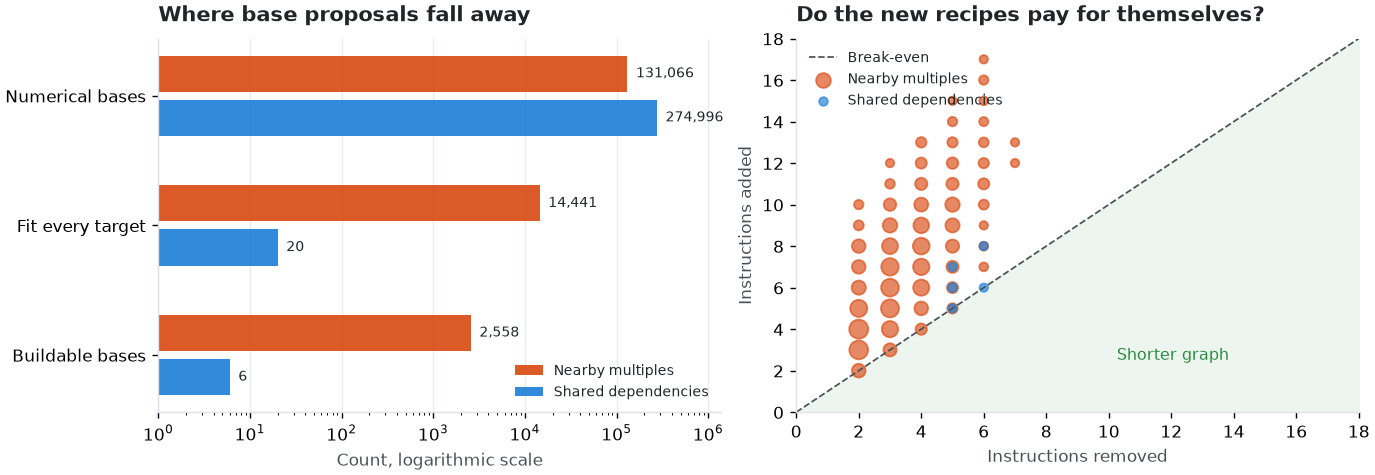

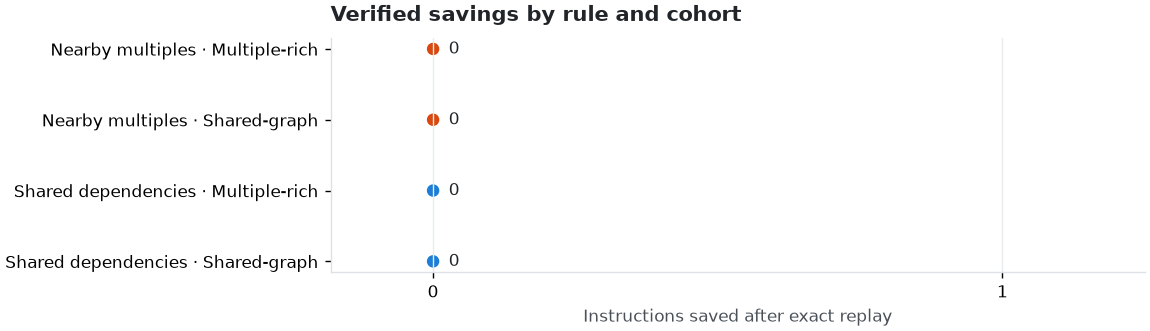

Pinned reference: 128,485 · 20 puzzles searched
Selection rule          Puzzles  Blocks      Bases    Fit all    Ready   Graphs   Shorter  Reg. rejects  Valid
Nearby multiples             12     294    131,066     14,441    2,558    3,175         0             0      0
  Two-step bases: 1,363 | Best graph delta: +0
  Closest block: scored_0127 | Base 646,271,325 | Removed 4, added 4
    646,271,332 = 1 × 646,271,325 +7
    5,170,169,800 = 8 × 646,271,325 -800
    646,271,321 = 1 × 646,271,325 -4
Shared dependencies          20     524    274,996         20        6        6         0             0      0
  Two-step bases: 3 | Best graph delta: +0
  Closest block: scored_0127 | Base 5,170,169,800 | Removed 5, added 5
    5,170,169,800 = 1 × 5,170,169,800 +0
    41,361,629,617 = 8 × 5,170,169,800 +271,217

Verified portfolio: 128,485 | Improved puzzles: 0 | 14.0s
This run exported no CSV because the verified score did not improve.


In [12]:
calculator = Calculator()
toy = Puzzle((1, 2, 3, 4, 10), frozenset({22, 33, 44}), 100, 48)
toy_tape = (
    ('*', 1, 4, 5), ('+', 5, 1, 5),
    ('*', 2, 4, 6), ('+', 6, 2, 6),
    ('*', 3, 4, 7), ('+', 7, 3, 7),
)
calculator.replay(toy, toy_tape)
toy_graph = ProgramGraph.from_program(toy, toy_tape)
check = AffineSearch(calculator).search(
    toy, toy_tape, toy_graph, tuple(sorted(toy_graph.roots)), Counter(), [], [], 'toy',
)
assert calculator.replay(toy, check).length <= 4

started = perf_counter()
portfolio = PortfolioPipeline(Config.discover())
result = AffinePilot(portfolio).run()
StudyReport.summary(portfolio, result, started)

## 4 · What the pilot showed

Nearby multiples yielded 3,175 concrete graph candidates. Selecting by shared dependencies yielded six. The best graph in either arm tied the reference in instruction count, so no candidate reached register allocation on scored data.

The two selection rules produced different kinds of blocks. Arithmetic proximity often gave a common-base representation, including for the break-even example scored_0127. A shared dependency in the reference graph rarely gave a block compatible with one affordable base under this search. A follow-up for those groups would need a broader recipe family, such as two cooperating intermediate values or a separate factorization for one branch. The result applies to these 20 puzzles and the bounds above.
